# 08 — Monte Carlo Trade Simulator

Notebook này tập trung vào 3 việc:
- mô phỏng đường giá tương lai bằng bootstrap historical returns
- xem fan chart và phân phối lợi nhuận sau logic stop/target
- so sánh nhanh vài kịch bản risk/reward cho cùng một mã


In [1]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Current working directory:", os.getcwd())


Project root: /Users/jamesb/Desktop/vietnam-quant-research
Current working directory: /Users/jamesb/Desktop/vietnam-quant-research


In [2]:
# Cell: Import Monte Carlo Modules
import pandas as pd

from src.data.loaders import read_parquet, save_parquet
from src.features.returns import add_returns
from src.models.monte_carlo import (
    bootstrap_price_paths,
    monte_carlo_path_summary,
    monte_carlo_probability_table,
    monte_carlo_terminal_summary,
    monte_carlo_trade_stats,
    simulate_trade_exits,
)
from src.reporting.chart_factory import (
    monte_carlo_exit_histogram,
    monte_carlo_exit_timeline_chart,
    monte_carlo_fan_chart,
    monte_carlo_percentile_cone_chart,
    monte_carlo_probability_bar_chart,
    monte_carlo_scenario_chart,
    monte_carlo_terminal_distribution_chart,
)


In [3]:
# Cell: Run Base Simulation
# CUSTOMIZABLE: Change the symbol ticker here to run simulations on a specific stock of your choice
symbol = "HPG"
stop_pct = 0.01
target_pct = 0.20
horizon_days = 60
simulations = 100000
random_state = 42
return_thresholds = (-0.10, -0.05, 0.0, 0.05, 0.10, 0.15)
clean = read_parquet("data/processed/clean_daily_ohlcv.parquet")
features = add_returns(clean) if "return_1d" not in clean.columns else clean.copy()
symbol_df = (
    features[features["symbol"].str.upper() == symbol.upper()]
    .sort_values("date")
    .copy()
)
if symbol_df.empty:
    raise ValueError(f"Khong tim thay du lieu cho ma {symbol}")
returns = symbol_df["return_1d"].dropna()
entry = float(symbol_df["close"].iloc[-1])
stop = entry * (1 - stop_pct)
target = entry * (1 + target_pct)
print(f"Auto-configured parameters for {symbol}:")
print(f"  Entry Price: {entry:,.2f} VND")
print(f"  Stop Loss:   {stop:,.2f} VND (-{stop_pct:.1%})")
print(f"  Target Price:{target:,.2f} VND (+{target_pct:.1%})")
paths = bootstrap_price_paths(
    returns,
    start_price=entry,
    horizon_days=horizon_days,
    simulations=simulations,
    random_state=random_state,
)
exits = simulate_trade_exits(paths, entry=entry, stop=stop, target=target)
stats = monte_carlo_trade_stats(paths, entry=entry, stop=stop, target=target)
path_summary = monte_carlo_path_summary(
    paths,
    start_price=entry,
    quantiles=(0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99),
)
terminal_summary = monte_carlo_terminal_summary(paths, start_value=entry)
probability_table = monte_carlo_probability_table(
    paths,
    start_value=entry,
    stop=stop,
    target=target,
    return_thresholds=return_thresholds,
)
pd.DataFrame([stats]).T.rename(columns={0: "value"})

Auto-configured parameters for HPG:
  Entry Price: 20,600.00 VND
  Stop Loss:   20,394.00 VND (-1.0%)
  Target Price:24,720.00 VND (+20.0%)


,value
p_hit_target,0.30353
p_hit_stop,0.84410
p_target_before_stop,0.13051
p_stop_before_target,0.83695
expected_return,0.02081
median_return,-0.01000
var_95,-0.01000
cvar_95,-0.01000
best_5pct,0.20000
avg_exit_day,11.62435


In [4]:
# Cell: Summarize Exit Types
exits.groupby("exit_type").agg(
    simulations=("simulation", "count"),
    avg_exit_day=("exit_day", "mean"),
    avg_exit_return=("exit_return", "mean"),
    median_exit_return=("exit_return", "median"),
).sort_values("simulations", ascending=False)


,simulations,avg_exit_day,avg_exit_return,median_exit_return
exit_type,,,,
stop,83695,7.021722,-0.010000,-0.010000
target,13051,29.079151,0.200000,0.200000
time,3254,60.000000,0.094585,0.095011


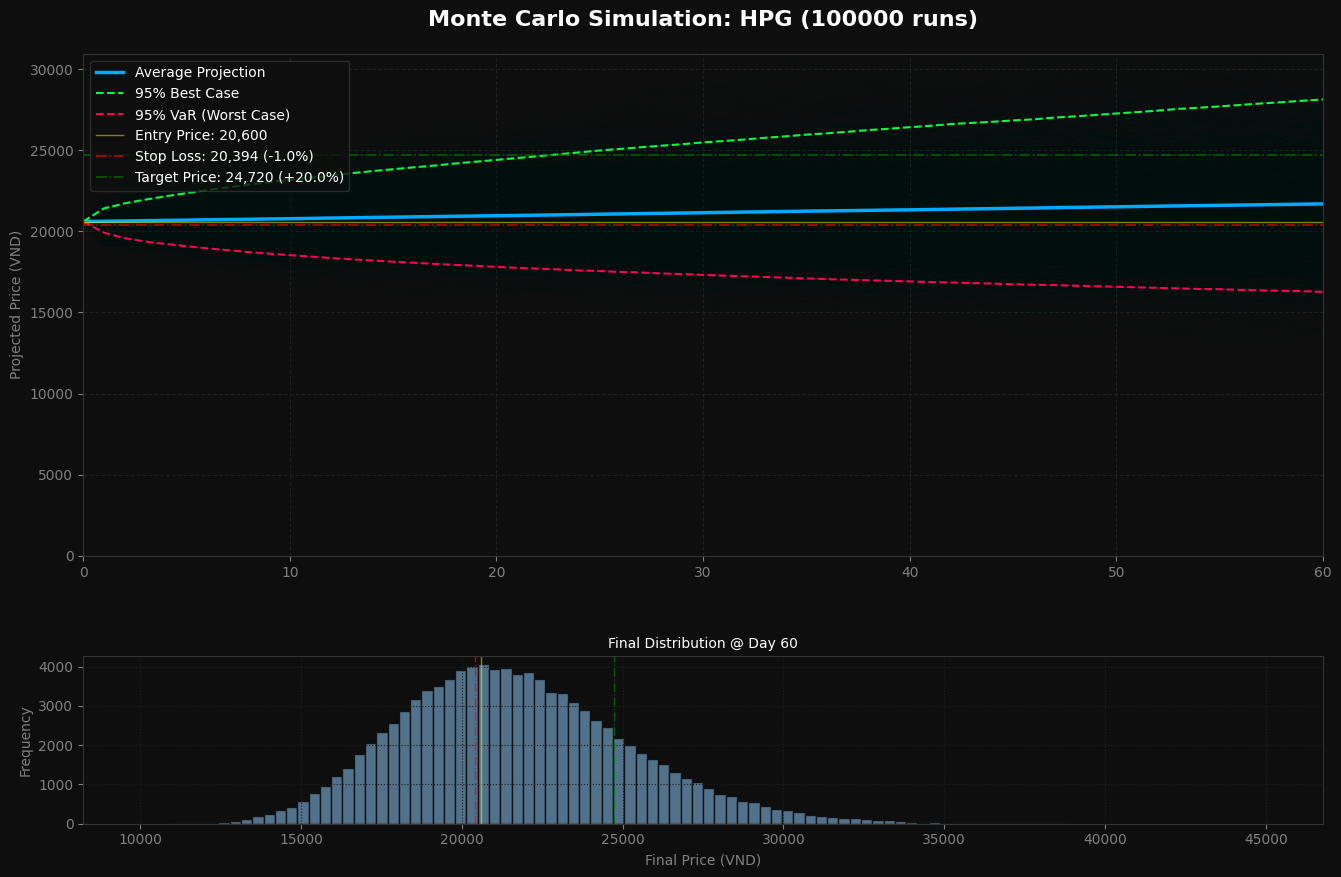

In [5]:
# Cell: Plot Pipeline-style Dark Theme Visualization
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np

# Prepare paths with Day 0 starting at entry
days = horizon_days + 1
day0 = np.full((1, paths.shape[0]), entry)
sim_paths = np.vstack([day0, paths.T])
final_values = sim_paths[-1, :]

# Statistics
mean_path = np.mean(sim_paths, axis=1)
upper_path = np.percentile(sim_paths, 95, axis=1)  # 95th percentile (Best Case)
lower_path = np.percentile(sim_paths, 5, axis=1)   # 5th percentile (VaR)

# Configuration for colors
COLOR_BG = '#0e0e0e'
COLOR_LINE = (0.0, 1.0, 1.0, 0.005) # Cyan, extremely low alpha for density cloud
COLOR_MEAN = '#00aaff'
COLOR_BEST = '#00ff41'
COLOR_WORST = '#ff0055'
COLOR_GRID = '#1f1f1f'

fig = plt.figure(figsize=(16, 10))
fig.patch.set_facecolor(COLOR_BG)
gs = GridSpec(2, 1, height_ratios=[3, 1], hspace=0.3)
ax_main = fig.add_subplot(gs[0])
ax_hist = fig.add_subplot(gs[1])

# 1. Trajectories Plot
ax_main.set_facecolor(COLOR_BG)
ax_main.grid(True, color=COLOR_GRID, linestyle='--')
ax_main.set_title(f"Monte Carlo Simulation: {symbol} ({simulations} runs)", 
                  color='white', fontsize=16, weight='bold', pad=20)
ax_main.set_ylabel("Projected Price (VND)", color='gray')
ax_main.tick_params(colors='gray')
for spine in ax_main.spines.values(): 
    spine.set_edgecolor('#333')

ax_main.set_xlim(0, days - 1)
ax_main.set_ylim(0, np.max(upper_path) * 1.1)

# Plot a subset of paths to show density cloud
step = max(1, simulations // 2000)
ax_main.plot(sim_paths[:, ::step], color=COLOR_LINE, linewidth=1.0)

# Stats Lines
x_axis = np.arange(days)
ax_main.plot(x_axis, mean_path, color=COLOR_MEAN, linewidth=2.5, label='Average Projection')
ax_main.plot(x_axis, upper_path, color=COLOR_BEST, linewidth=1.5, linestyle='--', label='95% Best Case')
ax_main.plot(x_axis, lower_path, color=COLOR_WORST, linewidth=1.5, linestyle='--', label='95% VaR (Worst Case)')

# Plot stop, entry, target lines
ax_main.axhline(y=entry, color='yellow', linestyle='-', linewidth=1.0, alpha=0.5, label=f'Entry Price: {entry:,.0f}')
ax_main.axhline(y=stop, color='red', linestyle='-.', linewidth=1.2, alpha=0.7, label=f'Stop Loss: {stop:,.0f} (-{stop_pct:.1%})')
ax_main.axhline(y=target, color='green', linestyle='-.', linewidth=1.2, alpha=0.7, label=f'Target Price: {target:,.0f} (+{target_pct:.1%})')

leg = ax_main.legend(loc='upper left', facecolor=COLOR_BG, edgecolor='#333')
for text in leg.get_texts(): 
    text.set_color('white')

# 2. Histogram Plot
ax_hist.set_facecolor(COLOR_BG)
ax_hist.grid(True, color=COLOR_GRID, linestyle=':')
ax_hist.set_xlabel("Final Price (VND)", color='gray')
ax_hist.set_ylabel("Frequency", color='gray')
ax_hist.tick_params(colors='gray')
for spine in ax_hist.spines.values(): 
    spine.set_edgecolor('#333')
ax_hist.set_title(f"Final Distribution @ Day {days-1}", color='white', fontsize=10)

ax_hist.hist(final_values, bins=100, color='#5a7d9a', edgecolor=COLOR_BG, alpha=0.9)
# Vertical lines in histogram
ax_hist.axvline(x=entry, color='yellow', linestyle='-', linewidth=1.0, alpha=0.5)
ax_hist.axvline(x=stop, color='red', linestyle='-.', linewidth=1.0, alpha=0.7)
ax_hist.axvline(x=target, color='green', linestyle='-.', linewidth=1.0, alpha=0.7)

plt.show()


In [6]:
# Cell: Plot Exit Histogram
hist_fig = monte_carlo_exit_histogram(
    exits,
    title=f"{symbol} Monte Carlo Exit Return Distribution",
)
display(hist_fig)
display(monte_carlo_terminal_distribution_chart(paths, start_value=entry, title=f"{symbol} Terminal Return Distribution"))
display(monte_carlo_exit_timeline_chart(exits, title=f"{symbol} Exit Timing Map"))


In [7]:
# Cell: Compare Risk Reward Scenarios
scenario_grid = [
    {"stop_pct": 0.03, "target_pct": 0.05},
    {"stop_pct": 0.04, "target_pct": 0.08},
    {"stop_pct": 0.05, "target_pct": 0.10},
    {"stop_pct": 0.06, "target_pct": 0.12},
]

rows = []
for scenario in scenario_grid:
    scenario_stop = entry * (1 - scenario["stop_pct"])
    scenario_target = entry * (1 + scenario["target_pct"])
    scenario_stats = monte_carlo_trade_stats(
        paths,
        entry=entry,
        stop=scenario_stop,
        target=scenario_target,
    )
    rows.append(
        {
            "stop_pct": scenario["stop_pct"],
            "target_pct": scenario["target_pct"],
            "risk_reward": round(scenario["target_pct"] / scenario["stop_pct"], 2),
            **scenario_stats,
        }
    )

scenario_df = pd.DataFrame(rows).sort_values(["expected_return", "p_target_before_stop"], ascending=False)
display(scenario_df)
monte_carlo_scenario_chart(scenario_df, title=f"{symbol} Monte Carlo Scenario Map")


,stop_pct,target_pct,risk_reward,p_hit_target,p_hit_stop,p_target_before_stop,p_stop_before_target,expected_return,median_return,var_95,cvar_95,best_5pct,avg_exit_day
3,0.06,0.12,2.00,0.52159,0.57443,0.41638,0.53571,0.019261,-0.06,-0.06,-0.06,0.12,21.18433
2,0.05,0.10,2.00,0.58672,0.62353,0.42860,0.55545,0.015489,-0.05,-0.05,-0.05,0.10,16.27087
1,0.04,0.08,2.00,0.65560,0.67311,0.43170,0.56560,0.011960,-0.04,-0.04,-0.04,0.08,11.79520
0,0.03,0.05,1.67,0.76388,0.72595,0.46636,0.53363,0.007309,-0.03,-0.03,-0.03,0.05,6.90768


In [8]:
# Cell: Review Terminal Probability Summary
terminal_wide = terminal_summary.set_index("metric").T
probability_table


,scenario,probability,odds_pct
0,Hit stop any time,0.84410,84.410
1,Terminal return >= 0%,0.58980,58.980
2,Terminal above entry,0.58980,58.980
3,Terminal return >= 5%,0.47375,47.375
4,Terminal below entry,0.41020,41.020
5,Finish below stop,0.38605,38.605
6,Terminal return >= 10%,0.36281,36.281
7,Hit target any time,0.30353,30.353
8,Terminal return <= -5%,0.29487,29.487
9,Terminal return >= 15%,0.26785,26.785


In [9]:
# Cell: Plot Probability Map
display(monte_carlo_probability_bar_chart(probability_table, title=f"{symbol} Monte Carlo Probability Map"))
display(terminal_wide)


metric,simulations,start_value,mean_terminal_value,median_terminal_value,expected_return,median_return,std_terminal_return,terminal_q01,return_q01,terminal_q05,...,terminal_q25,return_q25,terminal_q50,return_q50,terminal_q75,return_q75,terminal_q95,return_q95,terminal_q99,return_q99
value,100000.0,20600.0,21686.943345,21396.679888,0.052764,0.038674,0.176478,14437.850641,-0.299133,16268.337605,...,19131.06065,-0.071308,21396.679888,0.038674,23902.725733,0.160326,28127.230906,0.3654,31587.676138,0.533382


In [10]:
# Cell: Save Monte Carlo Outputs
# Notebook-only scratch output (single symbol, overwritten every run) -- not
# read by any production script (confirmed via grep,
# docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md NV1). Kept out of
# data/signals/ on purpose so it can never be mistaken for -- or collide
# with -- a real production signal file.
save_parquet(exits, "notebooks/outputs/monte_carlo_exits.parquet")
save_parquet(path_summary, "notebooks/outputs/monte_carlo_path_summary.parquet")
save_parquet(probability_table, "notebooks/outputs/monte_carlo_probability_table.parquet")
save_parquet(terminal_summary, "notebooks/outputs/monte_carlo_terminal_summary.parquet")
print("Saved Monte Carlo outputs to notebooks/outputs/")


Saved Monte Carlo outputs to notebooks/outputs/


In [11]:
# Cell: Monte Carlo Readout
summary_card = {
    "symbol": symbol,
    "entry": entry,
    "stop": stop,
    "target": target,
    "horizon_days": horizon_days,
    "simulations": simulations,
    "p_target_before_stop": stats["p_target_before_stop"],
    "p_stop_before_target": stats["p_stop_before_target"],
    "p_hit_target": stats["p_hit_target"],
    "p_hit_stop": stats["p_hit_stop"],
    "expected_return": stats["expected_return"],
    "median_return": stats["median_return"],
    "var_95": stats["var_95"],
    "cvar_95": stats["cvar_95"],
    "best_5pct": stats["best_5pct"],
    "worst_5pct": stats["var_95"],  # worst_5pct is equivalent to var_95
    "avg_exit_day": stats["avg_exit_day"],
}
pd.DataFrame([summary_card]).T.rename(columns={0: "value"})


,value
symbol,HPG
entry,20600.0
stop,20394.0
target,24720.0
horizon_days,60
simulations,100000
p_target_before_stop,0.13051
p_stop_before_target,0.83695
p_hit_target,0.30353
p_hit_stop,0.8441
